# Práctica 3 · Naive Bayes y SVM

Objetivo: relacionar supuestos, representación y errores. Wine conserva exactamente la partición de la práctica 2. La comparación sobre lunas es una demostración separada.

**Fuentes:** Géron, 3.ª ed., caps. 2–5; Grus, 2.ª ed., caps. 13–16; Gallatin y Albon, Cookbook adjunto, caps. 3–6 (preprocesamiento). Las consignas y los datos sintéticos son elaboración didáctica. Véase `../apuntes.md` y `../datos/README.md`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
ROOT = Path.cwd()
if not (ROOT / 'datos').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'datos').is_dir():
    raise FileNotFoundError('Abra el notebook desde la carpeta del subtema o desde notebooks, conservando datos/.')
print('Versiones:', sklearn.__version__, np.__version__, pd.__version__)

Versiones: 1.8.0 2.3.5 2.2.3


In [2]:
df = pd.read_csv(ROOT / 'datos/wine.csv')
features = [c for c in df.columns if c not in ['clase', 'particion']]
train = df[df.particion == 'entrenamiento']
val = df[df.particion == 'validacion']
Xtr, ytr = train[features], train.clase
Xv, yv = val[features], val.clase
print('Entrenamiento:', Xtr.shape, 'Validación:', Xv.shape)

Entrenamiento: (106, 13) Validación: (36, 13)


In [3]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score,classification_report
for name,est in [('GaussianNB',GaussianNB()),('SVM lineal',SVC(kernel='linear',C=1)),('SVM RBF',SVC(kernel='rbf',C=1,gamma='scale'))]:
    m=make_pipeline(StandardScaler(),est);m.fit(Xtr,ytr);pr=m.predict(Xv)
    print(name,'F1 macro de validación:',round(f1_score(yv,pr,average='macro'),4))
    print(classification_report(yv,pr,zero_division=0,digits=3))

GaussianNB F1 macro de validación: 0.9475
              precision    recall  f1-score   support

           0      1.000     0.833     0.909        12
           1      0.875     1.000     0.933        14
           2      1.000     1.000     1.000        10

    accuracy                          0.944        36
   macro avg      0.958     0.944     0.947        36
weighted avg      0.951     0.944     0.944        36

SVM lineal F1 macro de validación: 0.9457
              precision    recall  f1-score   support

           0      1.000     0.917     0.957        12
           1      0.875     1.000     0.933        14
           2      1.000     0.900     0.947        10

    accuracy                          0.944        36
   macro avg      0.958     0.939     0.946        36
weighted avg      0.951     0.944     0.945        36

SVM RBF F1 macro de validación: 0.9457
              precision    recall  f1-score   support

           0      1.000     0.917     0.957        12
      

**Ejercicio P3-A:** ¿por qué GaussianNB es una variante compatible con variables continuas? ¿Qué independencia presupone? Compare errores por clase antes de emitir una preferencia.

## 2. Fronteras SVM
Lunas sintéticas con partición independiente 70/30. Estas métricas no se comparan con Wine.

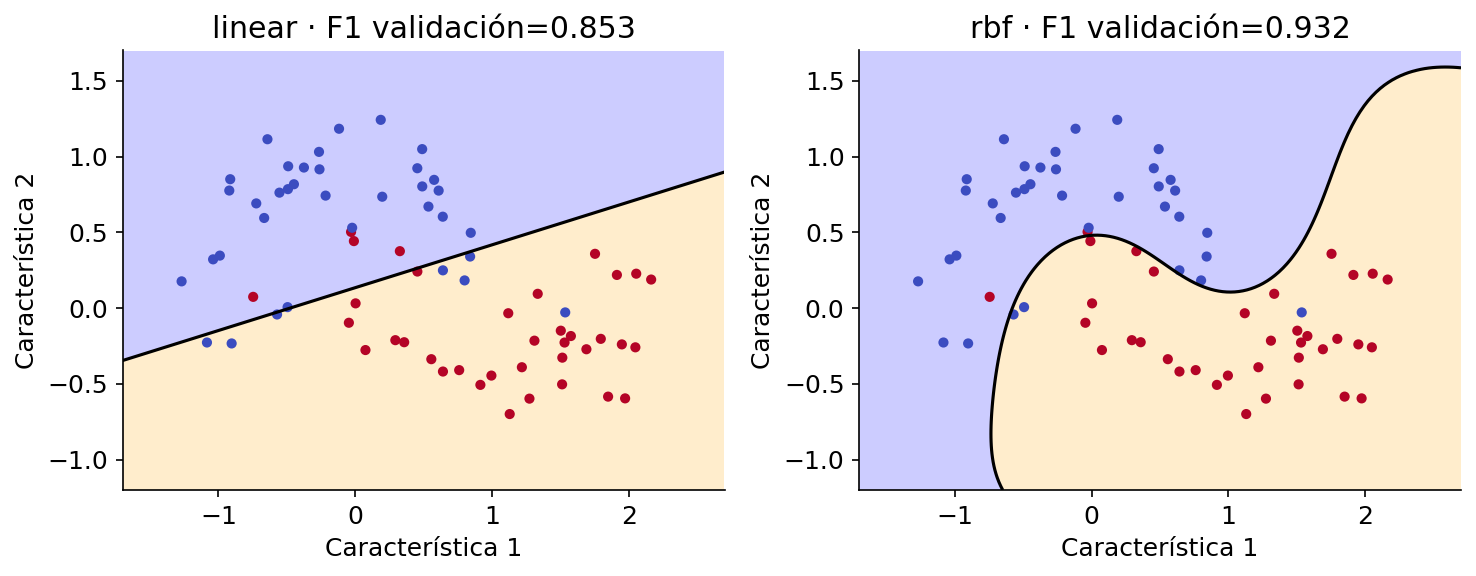

In [4]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
X,y=make_moons(n_samples=240,noise=.22,random_state=43)
Xt,Xv2,yt,yv2=train_test_split(X,y,test_size=.3,random_state=43,stratify=y)
xx,yy=np.meshgrid(np.linspace(-1.7,2.7,150),np.linspace(-1.2,1.7,110))
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,k in zip(axs,['linear','rbf']):
    m=make_pipeline(StandardScaler(),SVC(kernel=k,C=1,gamma='scale')).fit(Xt,yt)
    z=m.decision_function(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx,yy,z,levels=[-100,0,100],alpha=.2,colors=['blue','orange'])
    ax.contour(xx,yy,z,levels=[0],colors=['black'])
    ax.scatter(Xv2[:,0],Xv2[:,1],c=yv2,s=15,cmap='coolwarm')
    ax.set_title(k+' · F1 validación='+str(round(f1_score(yv2,m.predict(Xv2)),3)))
    ax.set_xlabel('Característica 1');ax.set_ylabel('Característica 2')
plt.tight_layout();plt.show()

## 3. Extensión de texto
Corpus de doce mensajes inventados. Solo demuestra un pipeline; no ofrece una evaluación representativa de un filtro real.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer
texts=['premio gratis ahora','gana dinero premio','oferta dinero gratis','premio oferta urgente','gana regalo gratis','oferta premio dinero',
 'reunion equipo hoy','informe proyecto listo','agenda reunion proyecto','equipo revisa informe','proyecto entrega manana','reunion agenda equipo']
labels=[1]*6+[0]*6
text_model=make_pipeline(CountVectorizer(),MultinomialNB(alpha=1))
text_model.fit(texts,labels)
print(text_model.predict(['premio dinero gratis','informe reunion equipo']))

[1 0]


**Entregable:** explique por qué MultinomialNB se usa con conteos no negativos y por qué StandardScaler no debe aplicarse sin criterio antes de esa variante.

**Extensión P3-B:** varíe C o gamma en las lunas, manteniendo particiones. Describa geometría y errores; no elija un ganador utilizando Wine y lunas como si fueran el mismo experimento.